# Deep Learning Laboratory - Experiment 09

## LSTM Text Generation

This is a standalone notebook for this lab section. Run the setup and dataset cells first, then run the experiment cell and its output check. Use a Colab GPU runtime for the image and generative-model experiments when available.


## Step 1 — Install the Additional Colab Packages

Wait until installation completes before the next cell starts.

In [ ]:
%pip -q install -U datasets "transformers<5" sentencepiece accelerate torchmetrics torch-fidelity ucimlrepo tabulate


## Step 2 — Verify the Runtime

This cell records the Python, TensorFlow, and PyTorch versions and enables safe TensorFlow GPU memory growth.

In [ ]:
from pathlib import Path
import platform
import tensorflow as tf
import torch

project_root = Path("/content/Deeplearning")
project_root.mkdir(parents=True, exist_ok=True)
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print(f"Python: {platform.python_version()}")
print(f"TensorFlow: {tf.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Project root: {project_root}")


Python: 3.13.15
TensorFlow: 2.20.0
PyTorch: 2.11.0+cu128
CUDA available: True
Project root: /content/Deeplearning


## Step 3 — Import Every Required Dataset

This cell creates visible files under `/content/Deeplearning/datasets` and prints a manifest that can be shown to the staff.

- MNIST, Iris, CIFAR-10, Dogs vs. Cats, Airline Passengers, and Tiny Shakespeare are downloaded as complete or balanced lab-ready files.
- MS COCO, CelebA, and LSUN Bedrooms are the genuine named datasets, streamed as practical subsets for Colab.
- No synthetic replacement dataset is used.

In [ ]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from datasets import load_dataset
from sklearn.datasets import load_iris


root = Path("/content/Deeplearning") if Path("/content").exists() else Path(__file__).resolve().parent
dataset_dir = root / "datasets"
output_dir = root / "outputs"
dataset_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)


def balanced_indices(labels, per_class, seed):
    labels = np.asarray(labels).reshape(-1)
    indices = np.concatenate([np.flatnonzero(labels == class_index)[:per_class] for class_index in np.unique(labels)])
    rng = np.random.default_rng(seed)
    rng.shuffle(indices)
    return indices


def save_image_stream(dataset_name, split, destination, count, size, config=None):
    destination.mkdir(parents=True, exist_ok=True)
    existing = sorted(destination.glob("*.jpg"))
    if len(existing) >= count:
        return len(existing)
    arguments = {
        "path": dataset_name,
        "split": split,
        "streaming": True,
    }
    if config is not None:
        arguments["name"] = config
    stream = load_dataset(**arguments)
    saved = 0
    for row in stream.take(count):
        image = row["image"].convert("RGB")
        image = image.resize((size, size), Image.Resampling.LANCZOS)
        image.save(destination / f"image_{saved:04d}.jpg", quality=92)
        saved += 1
    if saved < count:
        raise RuntimeError(f"Only {saved} images were available from {dataset_name}")
    return saved


(mnist_x_train, mnist_y_train), (mnist_x_test, mnist_y_test) = tf.keras.datasets.mnist.load_data()
mnist_train_indices = balanced_indices(mnist_y_train, 1000, 42)
mnist_test_indices = balanced_indices(mnist_y_test, 200, 42)
np.savez_compressed(
    dataset_dir / "mnist_lab.npz",
    x_train=mnist_x_train[mnist_train_indices],
    y_train=mnist_y_train[mnist_train_indices],
    x_test=mnist_x_test[mnist_test_indices],
    y_test=mnist_y_test[mnist_test_indices],
)

try:
    from ucimlrepo import fetch_ucirepo

    iris_repository = fetch_ucirepo(id=53)
    iris_features = iris_repository.data.features.copy()
    iris_features.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    iris_target = iris_repository.data.targets.iloc[:, 0].astype(str)
    iris_target = iris_target.str.replace("Iris-", "", regex=False).str.replace("Iris ", "", regex=False).str.lower()
    iris = iris_features.copy()
    iris["species"] = iris_target.to_numpy()
    iris_source = "UCI Machine Learning Repository dataset 53"
except Exception:
    iris_bundle = load_iris(as_frame=True)
    iris = iris_bundle.data.copy()
    iris.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    iris["species"] = pd.Series(iris_bundle.target).map(dict(enumerate(iris_bundle.target_names)))
    iris_source = "scikit-learn packaged Iris fallback"
iris.to_csv(dataset_dir / "iris.csv", index=False)

(cifar_x_train, cifar_y_train), (cifar_x_test, cifar_y_test) = tf.keras.datasets.cifar10.load_data()
cifar_train_indices = balanced_indices(cifar_y_train, 800, 42)
cifar_test_indices = balanced_indices(cifar_y_test, 200, 42)
np.savez_compressed(
    dataset_dir / "cifar10_lab.npz",
    x_train=cifar_x_train[cifar_train_indices],
    y_train=cifar_y_train[cifar_train_indices].reshape(-1),
    x_test=cifar_x_test[cifar_test_indices],
    y_test=cifar_y_test[cifar_test_indices].reshape(-1),
)

def build_cats_and_dogs_filtered(destination, image_size=160, seed=42):
    """Rebuild the classic 'cats_and_dogs_filtered' train/validation layout.

    The original tutorial archive at
    https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip
    now returns HTTP 403 (Google retired the mledu-datasets bucket), so the
    same 3,000-image split is reconstructed by streaming labelled images
    from the public "microsoft/cats_vs_dogs" dataset on the Hugging Face Hub.
    """
    targets = {
        destination / "train" / "cats": (0, 1000),
        destination / "train" / "dogs": (1, 1000),
        destination / "validation" / "cats": (0, 500),
        destination / "validation" / "dogs": (1, 500),
    }
    already_done = all(
        len(list(folder.glob("*.jpg"))) >= count for folder, (_, count) in targets.items()
    )
    if already_done:
        return destination
    for folder in targets:
        folder.mkdir(parents=True, exist_ok=True)
    counts = {folder: 0 for folder in targets}
    stream = load_dataset("microsoft/cats_vs_dogs", split="train", streaming=True)
    stream = stream.shuffle(seed=seed, buffer_size=2000)
    for row in stream:
        if all(counts[folder] >= count for folder, (_, count) in targets.items()):
            break
        label = row["labels"]
        for folder, (target_label, target_count) in targets.items():
            if label != target_label or counts[folder] >= target_count:
                continue
            try:
                image = row["image"].convert("RGB")
            except Exception:
                break
            image = image.resize((image_size, image_size), Image.Resampling.LANCZOS)
            image.save(folder / f"image_{counts[folder]:04d}.jpg", quality=92)
            counts[folder] += 1
            break
    for folder, (_, count) in targets.items():
        if counts[folder] < count:
            raise RuntimeError(f"Only {counts[folder]} images were available for {folder}")
    return destination


dogs_cats_dir = dataset_dir / "cats_and_dogs_filtered"
build_cats_and_dogs_filtered(dogs_cats_dir)
if not (dogs_cats_dir / "train").exists():
    raise FileNotFoundError("Dogs vs. Cats extraction folder was not created")

airline_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/monthly-airline-passengers.csv"
airline = pd.read_csv(airline_url)
airline.to_csv(dataset_dir / "monthly_airline_passengers.csv", index=False)

shakespeare_cache = tf.keras.utils.get_file(
    fname="shakespeare.txt",
    origin="https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt",
    cache_dir=str(root),
    cache_subdir="downloads",
)
shakespeare_path = dataset_dir / "shakespeare.txt"
shutil.copyfile(shakespeare_cache, shakespeare_path)

coco_dir = dataset_dir / "ms_coco_subset"
coco_dir.mkdir(parents=True, exist_ok=True)
coco_caption_path = coco_dir / "captions.csv"
if not coco_caption_path.exists() or len(list(coco_dir.glob("coco_*.jpg"))) < 5:
    coco_stream = load_dataset("mm-eval/MS-COCO-Captions", split="val", streaming=True)
    coco_rows = []
    for index, row in enumerate(coco_stream.take(5)):
        image_path = coco_dir / f"coco_{index:03d}.jpg"
        media = row["media"]
        image = media[0] if isinstance(media, list) else media
        image.convert("RGB").save(image_path, quality=92)
        coco_rows.append(
            {
                "file": image_path.name,
                "captions_json": json.dumps(list(row["answer"]), ensure_ascii=False),
            }
        )
    pd.DataFrame(coco_rows).to_csv(coco_caption_path, index=False)

celeba_dir = dataset_dir / "celeba_subset"
celeba_count = save_image_stream("flwrlabs/celeba", "train", celeba_dir, 384, 64, "img_align+identity+attr")

lsun_dir = dataset_dir / "lsun_bedrooms_subset"
lsun_count = save_image_stream("pcuenq/lsun-bedrooms", "train", lsun_dir, 512, 64)

manifest = pd.DataFrame(
    [
        {"dataset": "MNIST", "path": "mnist_lab.npz", "records": 12000, "experiments": "1", "source": "TensorFlow Keras MNIST", "scope": "Balanced lab subset"},
        {"dataset": "Iris", "path": "iris.csv", "records": len(iris), "experiments": "2", "source": iris_source, "scope": "Complete dataset"},
        {"dataset": "CIFAR-10", "path": "cifar10_lab.npz", "records": 10000, "experiments": "3, 4, Mini Project", "source": "TensorFlow Keras CIFAR-10", "scope": "Balanced lab subset"},
        {"dataset": "Dogs vs. Cats", "path": str(dogs_cats_dir.relative_to(dataset_dir)), "records": 3000, "experiments": "5", "source": "microsoft/cats_vs_dogs public mirror (Hugging Face)", "scope": "Filtered dataset (rebuilt 1000/1000 train, 500/500 validation)"},
        {"dataset": "Airline Passengers", "path": "monthly_airline_passengers.csv", "records": len(airline), "experiments": "6", "source": airline_url, "scope": "Complete dataset"},
        {"dataset": "MS COCO", "path": "ms_coco_subset", "records": 5, "experiments": "7", "source": "mm-eval/MS-COCO-Captions public parquet mirror", "scope": "Real-image demonstration subset"},
        {"dataset": "CelebA", "path": "celeba_subset", "records": celeba_count, "experiments": "8", "source": "flwrlabs/celeba public mirror", "scope": "Streamed training subset"},
        {"dataset": "Shakespeare Corpus", "path": "shakespeare.txt", "records": len(shakespeare_path.read_text(encoding="utf-8")), "experiments": "9", "source": "TensorFlow Tiny Shakespeare", "scope": "Complete corpus"},
        {"dataset": "LSUN Bedrooms", "path": "lsun_bedrooms_subset", "records": lsun_count, "experiments": "10", "source": "pcuenq/lsun-bedrooms public mirror", "scope": "Streamed training subset"},
    ]
)
manifest.to_csv(dataset_dir / "dataset_manifest.csv", index=False)

print(f"Deeplearning root: {root}")
print(manifest.to_string(index=False))
print("Dataset evidence:")
for path in sorted(dataset_dir.iterdir()):
    if path.is_dir():
        file_count = sum(1 for item in path.rglob("*") if item.is_file())
        print(f"{path.name}/: {file_count} files")
    else:
        print(f"{path.name}: {path.stat().st_size} bytes")


Deeplearning root: /content/Deeplearning
           dataset                           path  records        experiments                                                                                                source                                                          scope
             MNIST                  mnist_lab.npz    12000                  1                                                                                TensorFlow Keras MNIST                                            Balanced lab subset
              Iris                       iris.csv      150                  2                                                            UCI Machine Learning Repository dataset 53                                               Complete dataset
          CIFAR-10                cifar10_lab.npz    10000 3, 4, Mini Project                                                                             TensorFlow Keras CIFAR-10                                            Balance

# Experiment 9 — LSTM Text Generation

**Dataset:** Tiny Shakespeare

**Procedure:** Trains a character-level LSTM, calculates perplexity, and generates Shakespeare-style text.

Run the cell and wait for the completion message. The model, numerical results, and plots are written to the corresponding folder under `/content/Deeplearning/outputs`.

Epoch 1/2
521/521 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.2615 - loss: 2.7272
Epoch 2/2
521/521 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3528 - loss: 2.2552


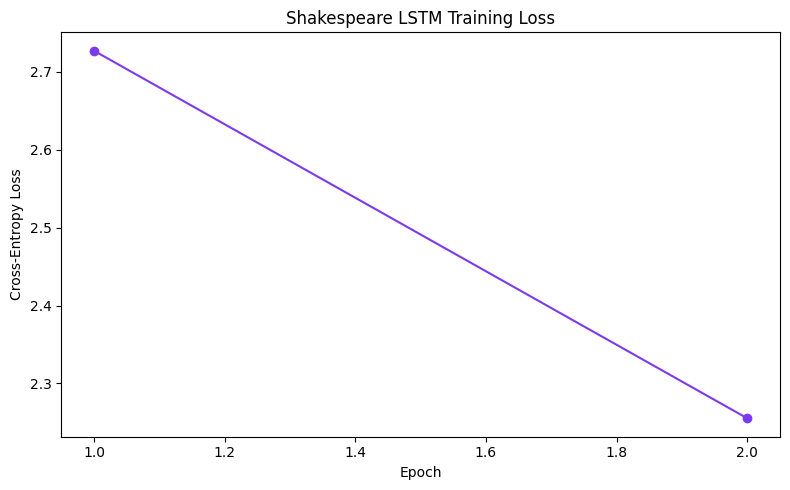

Experiment 9 completed
Corpus characters used: 200000
Vocabulary size: 62
Final perplexity: 9.5377
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

GUENToMAL
RAER Rary,
Ald fase sule hitey tha! andave
Lou her' urterceed tuut :
ond wofr corg forave dong benome wend thay thte of the mall: the wall the lar a cile de dlou
Matt rethe ougtur wcop in thar ste eards: nort, ind maceed soull oun pove the fyauche ceard of aad an hime, ould mingsy an treepterll dour the my ar as ins pet the aris pesttoll-dinaled, leazer:
Lhand bey sowh rath to pold ham' bot feadd mede.

AUCENNDUS:
Nate ssifg whar and.
Will the cound fyon hy begees wavl sin it the dot
Output folder: /content/Deeplearning/outputs/experiment_09


In [ ]:
from pathlib import Path
import gc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf


try:
    import torch

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
except Exception:
    pass
gc.collect()

root = Path("/content/Deeplearning") if Path("/content").exists() else Path(__file__).resolve().parents[1]
dataset_path = root / "datasets" / "shakespeare.txt"
output_dir = root / "outputs" / "experiment_09"
output_dir.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(42)

text = dataset_path.read_text(encoding="utf-8")[:200000]
vocabulary = sorted(set(text))
character_to_index = {character: index for index, character in enumerate(vocabulary)}
index_to_character = np.array(vocabulary)
sequence_length = 80
stride = 3
starts = range(0, len(text) - sequence_length, stride)
sequences = np.array([[character_to_index[character] for character in text[start : start + sequence_length]] for start in starts], dtype="int16")
targets = np.array([character_to_index[text[start + sequence_length]] for start in starts], dtype="int16")
dataset = tf.data.Dataset.from_tensor_slices((sequences, targets)).shuffle(10000, seed=42).batch(128).prefetch(tf.data.AUTOTUNE)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(sequence_length,)),
        tf.keras.layers.Embedding(len(vocabulary), 64),
        tf.keras.layers.LSTM(128),
        tf.keras.layers.Dense(len(vocabulary)),
    ]
)
model.compile(optimizer="adam", loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
history = model.fit(dataset, epochs=2, verbose=1)
history_frame = pd.DataFrame(history.history)
history_frame.insert(0, "epoch", np.arange(1, len(history_frame) + 1))
history_frame["perplexity"] = np.exp(history_frame["loss"])
history_frame.to_csv(output_dir / "lstm_training_history.csv", index=False)
model.save(output_dir / "shakespeare_lstm.keras")


def sample_character(logits, temperature):
    adjusted = tf.convert_to_tensor(logits, dtype=tf.float32)[tf.newaxis, :] / temperature
    return int(tf.random.categorical(adjusted, num_samples=1)[0, 0].numpy())


seed_text = text[:sequence_length]
generated = seed_text
window = [character_to_index[character] for character in seed_text]
temperature = 0.8
for _ in range(500):
    logits = model.predict(np.array([window]), verbose=0)[0]
    next_index = sample_character(logits, temperature)
    next_character = index_to_character[next_index]
    generated += next_character
    window = window[1:] + [next_index]

(output_dir / "generated_shakespeare.txt").write_text(generated, encoding="utf-8")

figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(history_frame["epoch"], history_frame["loss"], marker="o", color="#7c3aed")
axis.set_title("Shakespeare LSTM Training Loss")
axis.set_xlabel("Epoch")
axis.set_ylabel("Cross-Entropy Loss")
figure.tight_layout()
figure.savefig(output_dir / "lstm_training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

print("Experiment 9 completed")
print(f"Corpus characters used: {len(text)}")
print(f"Vocabulary size: {len(vocabulary)}")
print(f"Final perplexity: {history_frame['perplexity'].iloc[-1]:.4f}")
print(generated)
print(f"Output folder: {output_dir}")


## Output check

Confirm that this experiment saved its results before moving on.

In [ ]:
from pathlib import Path
output_dir = Path('/content/Deeplearning/outputs/experiment_09')
files = sorted(path for path in output_dir.rglob('*') if path.is_file())
assert files, f'No outputs found in {output_dir}; run the experiment cell first.'
print(f'{len(files)} output files saved in {output_dir}')
for path in files:
    print(path.relative_to(output_dir))
